# UICT Student Success Early Warning: analysis walkthrough

This notebook runs the **same pipeline as `analysis.py`**, broken into small steps with an explanation before each one. It uses the same data, the same at-risk definition, the same features and the same `random_state=42`, so every number here matches the script.

**The question:** Can we spot students who are at risk of failing **before** their exams, using only their coursework marks, so the institute has time to help them?

**Sections**
0. Data cleaning
1. Descriptive: *what happened?*
2. Diagnostic: *why did it happen?*
3. Predictive: *what will happen?* (a trained model)
4. Prescriptive: *what should we do about it?*
5. Appendix: context datasets (LMS usage, digital-skills survey)

### Setup: libraries and constants
**What:** imports the tools we need. `pandas` handles tables, `numpy` does maths, `scikit-learn` (`sklearn`) builds the models, `matplotlib` draws charts and `joblib` saves the model to a file.

**Why:** `CUS` is the list of the 6 course units (CU1 to CU6). The data portal does not give their real names, so we only know them by number. `OUT` is a dictionary that collects every result, just as in `analysis.py`.

We also pick two chart colours (blue and orange) and use them the same way in every chart.

In [2]:
import json, re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
import joblib
import matplotlib.pyplot as plt

UP = "./"
CUS = [f"CU{i}" for i in range(1, 7)]
OUT = {}

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})

---
## 0. Data cleaning

Raw data is rarely ready to analyse. This section turns two messy CSV files into one clean table with **one row per student**.

Each course unit has four columns:
- `CW`: coursework mark, **out of 40**
- `EX`: exam mark, **out of 60**
- `MK`: final mark (CW + EX), out of 100
- `GP`: grade point for that unit (0 to 5)

### Step 0.1: a function that loads and cleans one programme file
**What it does:**
1. Keeps only rows whose student number starts with "S". This removes junk rows such as `#N/A`.
2. Handles marks like **`50*`**. The star marks a retake/supplementary result. We do two things with it:
   - **keep the number** (50) so we can still do maths with it, and
   - **record the star** in a new column `CUx_RETAKE` (1 = starred, 0 = not), so the information is not lost.
3. Converts every mark column to a number. Anything that cannot be converted (blank cells) becomes `NaN`, meaning "missing".

**Why:** if we left `50*` as text, Python could not average it. If we simply deleted the star, we would lose the fact that the student needed a retake, and that is a strong sign of risk.

In [2]:
def load_perf(path):
    df = pd.read_csv(UP + path)
    df = df[df.STUDENT_NO.str.startswith("S", na=False)].copy()      # drop "#N/A" rows
    for cu in CUS:
        # "50*" = retake / supplementary mark. Keep the number, flag the retake.
        mk = df[f"{cu}_MK"].astype(str)
        df[f"{cu}_RETAKE"] = mk.str.contains(r"\*").astype(int)
        for part in ["CW", "EX", "MK", "GP"]:
            df[f"{cu}_{part}"] = pd.to_numeric(
                df[f"{cu}_{part}"].astype(str).str.replace("*", "", regex=False), errors="coerce")
    return df

### Step 0.2: combine the two programmes
**What:** loads both files and stacks them into one table. Columns that carry no information are dropped: `Id`, `DataSetId`, and `SEMESTER`, which is empty.

**Note:** the file called "DITA…" actually holds **DITB** students. Its `STUDENT_PROGRAM` column says DITB, so we trust that column, not the file name.

**Output:** the number of student records before any exclusions.

In [3]:
perf = pd.concat([load_perf("DITA student persformance 2020 sem1.csv"),
                  load_perf("DITS student performance 2020 sem1.csv")], ignore_index=True)
perf = perf.drop(columns=["Id", "DataSetId", "SEMESTER"])
n_raw = len(perf)
print("Student records:", n_raw)
print(perf.STUDENT_PROGRAM.value_counts().to_dict())

Student records: 86
{'DITS': 46, 'DITB': 40}


### Step 0.3: exclude students with incomplete records
**What:** counts how many of the 6 units each student has a final mark for (`CUS_SAT`). Students with fewer than 6 are separated out.

**Why:** a student who has marks in only 1 or 2 units most likely **dropped out or deferred** mid-semester. We cannot judge their performance fairly. Filling in their missing marks would mean inventing data. So we **report** them (they are a risk group in their own right) but leave them **out of the model**.

**Output:** the 5 excluded students and how many units each has marks for. 86 − 5 = **81 complete students**.

In [4]:
# Students missing most marks probably dropped out mid-semester -> report them, exclude from model
perf["CUS_SAT"] = perf[[f"{c}_MK" for c in CUS]].notna().sum(axis=1)
dropouts = perf[perf.CUS_SAT < 6]
perf = perf[perf.CUS_SAT == 6].copy()
print("Complete students:", len(perf), "| excluded:", len(dropouts))
dropouts[["STUDENT_NO", "STUDENT_PROGRAM", "STUDY_TIME", "CUS_SAT"]]

Complete students: 81 | excluded: 5


,STUDENT_NO,STUDENT_PROGRAM,STUDY_TIME,CUS_SAT
20,S0000963,DITB,DAY,1
29,S0001049,DITB,WEEKEND,4
37,S0001150,DITB,DAY,2
63,S0000697,DITS,EVENING,1
82,S0001088,DITS,DAY,3


### Step 0.4: summary columns and the **target** (`AT_RISK`)
**What:** builds one summary number per student:
- `AVG_MARK`: average final mark across the 6 units
- `CGPA`: average grade point (this semester only)
- `AVG_CW`: average coursework mark
- `N_FAILS`: number of units with a final mark below 50
- `N_RETAKES`: number of starred (retake) marks

Then it defines the **target**, the thing we want to predict. A student is **at risk (1)** if *any* of these is true:
- failed at least one unit, **or**
- had to retake at least one unit, **or**
- CGPA is below 3.0 (the pass-class boundary)

Otherwise the student is **not at risk (0)**.

**Why this definition:** it captures students who are failing *and* students who are only just scraping through. Both groups benefit from early support.

**Output:** the share of students who are at risk.

In [5]:
mk_cols = [f"{c}_MK" for c in CUS]
cw_cols = [f"{c}_CW" for c in CUS]
ex_cols = [f"{c}_EX" for c in CUS]
perf["AVG_MARK"] = perf[mk_cols].mean(axis=1)
perf["CGPA"] = perf[[f"{c}_GP" for c in CUS]].mean(axis=1)
perf["AVG_CW"] = perf[cw_cols].mean(axis=1)
perf["N_FAILS"] = (perf[mk_cols] < 50).sum(axis=1)
perf["N_RETAKES"] = perf[[f"{c}_RETAKE" for c in CUS]].sum(axis=1)
# TARGET: at risk = failed or had to retake any course unit, or CGPA below 3.0 (pass-class boundary)
perf["AT_RISK"] = ((perf.N_FAILS > 0) | (perf.N_RETAKES > 0) | (perf.CGPA < 3.0)).astype(int)
perf.to_csv("clean_performance.csv", index=False)
print(perf.AT_RISK.value_counts().rename({0: "not at risk", 1: "at risk"}).to_dict(),
      f"-> {perf.AT_RISK.mean()*100:.1f}% at risk")

{'not at risk': 56, 'at risk': 25} -> 30.9% at risk


---
## 1. Descriptive analysis: *what happened?*

Here we summarise the semester: averages, at-risk rates, and how these differ by programme, sex and study mode. No modelling yet, just counting and averaging.

### Step 1.1: headline numbers
**What:** the overall averages and the at-risk rate.

**How to read it:** the average mark is about 67 and the average CGPA about 3.46. That sounds healthy, but **about 31% of students are at risk**. The averages hide a sizeable struggling group.

In [6]:
d = {}
d["students_total"] = int(n_raw)
d["students_complete"] = int(len(perf))
d["incomplete_records"] = int(len(dropouts))
d["avg_mark"] = round(perf.AVG_MARK.mean(), 1)
d["avg_cgpa"] = round(perf.CGPA.mean(), 2)
d["at_risk_rate"] = round(perf.AT_RISK.mean() * 100, 1)
{k: d[k] for k in ["students_total", "students_complete", "incomplete_records", "avg_mark", "avg_cgpa", "at_risk_rate"]}

{'students_total': 86,
 'students_complete': 81,
 'incomplete_records': 5,
 'avg_mark': np.float64(66.7),
 'avg_cgpa': np.float64(3.46),
 'at_risk_rate': np.float64(30.9)}

### Step 1.2: by programme (DITB vs DITS)
**What:** groups students by programme and computes the number of students, average mark, CGPA and at-risk rate. `at_risk` is a proportion, so 0.51 means 51%.

**How to read it:** this is the **biggest finding in the descriptive section**. About **51% of DITB students are at risk, against 14% of DITS students**. DITB students score lower on average in almost every unit.

In [7]:
d["by_program"] = perf.groupby("STUDENT_PROGRAM").agg(
    n=("AVG_MARK", "size"), avg_mark=("AVG_MARK", "mean"), cgpa=("CGPA", "mean"),
    at_risk=("AT_RISK", "mean")).round(2).reset_index().to_dict("records")
pd.DataFrame(d["by_program"])

,STUDENT_PROGRAM,n,avg_mark,cgpa,at_risk
0,DITB,37,63.10,3.12,0.51
1,DITS,44,69.77,3.75,0.14


### Step 1.3: average mark per course unit, by programme
**What:** the average final mark in each of the 6 units, separately for DITB and DITS.

**How to read the chart:** look for the unit where a bar drops. **CU6 is clearly the hardest unit for DITB** (about 53, only just above the pass mark of 50). DITS is ahead of DITB in five of the six units. CU2 is the exception, where DITB is slightly higher. The dashed line is the pass mark.

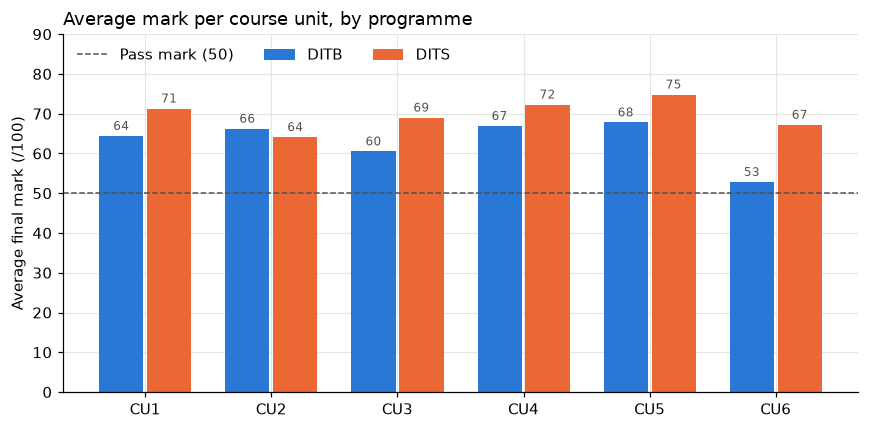

In [8]:
d["cu_avg"] = {p: perf[perf.STUDENT_PROGRAM == p][mk_cols].mean().round(1).tolist()
               for p in perf.STUDENT_PROGRAM.unique()}

x = np.arange(len(CUS)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for i, (prog, col) in enumerate([("DITB", BLUE), ("DITS", ORANGE)]):
    bars = ax.bar(x + (i - 0.5) * w, d["cu_avg"][prog], w - 0.03, color=col, label=prog)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, color="#52514e", padding=2)
ax.axhline(50, color="#52514e", ls="--", lw=1, label="Pass mark (50)")
ax.set_xticks(x, CUS); ax.set_ylim(0, 90); ax.set_ylabel("Average final mark (/100)")
ax.set_title("Average mark per course unit, by programme", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

### Step 1.4: coursework vs exam, per unit (as % of the maximum)
**What:** coursework is marked out of 40 and exams out of 60, so raw marks cannot be compared directly. We convert both to a **percentage of the maximum**. For example, 30/40 = 75% and 36/60 = 60%.

**How to read the chart:** in **every unit, students score a higher percentage in coursework than in the exam**. The gap is widest in **CU6**, where students average about 74% in coursework but only about 52% in the exam. **Marks are mainly lost in exams.** This is why coursework can act as an early warning: weak coursework comes *before* a weak exam.

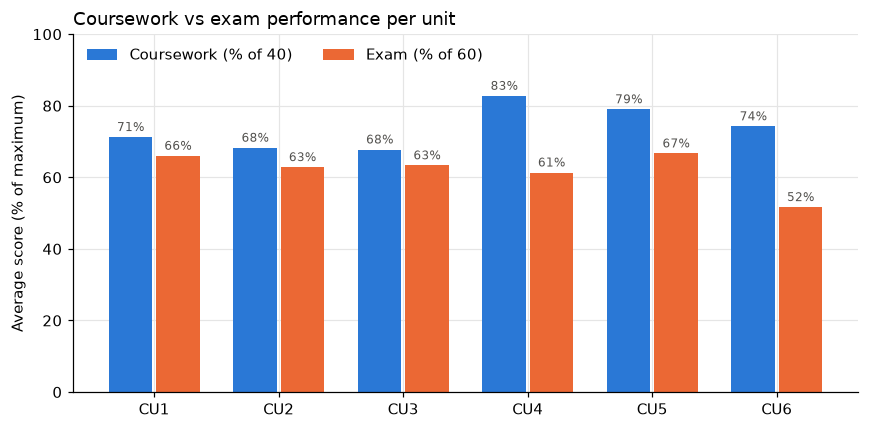

In [9]:
d["cu_cw_ex"] = {"cw": perf[cw_cols].mean().round(1).tolist(), "ex": perf[ex_cols].mean().round(1).tolist()}
cw_pct = np.array(d["cu_cw_ex"]["cw"]) / 40 * 100
ex_pct = np.array(d["cu_cw_ex"]["ex"]) / 60 * 100

fig, ax = plt.subplots(figsize=(8, 4))
for i, (vals, col, lab) in enumerate([(cw_pct, BLUE, "Coursework (% of 40)"), (ex_pct, ORANGE, "Exam (% of 60)")]):
    bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.03, color=col, label=lab)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, CUS); ax.set_ylim(0, 100); ax.set_ylabel("Average score (% of maximum)")
ax.set_title("Coursework vs exam performance per unit", loc="left")
ax.legend(frameon=False, ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

### Step 1.5: distribution of all marks
**What:** puts every individual unit mark (81 students × 6 units = 486 marks) into grade bands.

**How to read it:** very few marks fall below 50 (outright fails are rare). Many sit in the 50–59 band, just above the pass line. This is why our at-risk definition also includes retakes and CGPA < 3.0. Counting outright fails alone would miss most of the struggling students.

In [10]:
bins = [0, 50, 60, 70, 80, 101]; labels = ["<50", "50-59", "60-69", "70-79", "80+"]
d["mark_dist"] = pd.cut(perf[mk_cols].values.ravel(), bins, labels=labels, right=False
                        ).value_counts().reindex(labels).astype(int).tolist()
d["mark_dist_labels"] = labels
dict(zip(labels, d["mark_dist"]))

{'<50': 6, '50-59': 121, '60-69': 146, '70-79': 155, '80+': 58}

### Step 1.6: by sex and by study mode
**What:** the same summary, split by sex (F/M) and by study time (Day/Evening/Weekend).

**How to read it:** the at-risk rate is higher for males than for females (34% vs 21%) and higher for evening students (44%). But the groups are small: only **19 women** and **16 evening students**. One or two students more or less would change these percentages a lot, so treat them as hints, not conclusions.

In [11]:
d["by_sex"] = perf.groupby("STUDENT_SEX").agg(n=("CGPA", "size"), cgpa=("CGPA", "mean"),
              at_risk=("AT_RISK", "mean")).round(2).reset_index().to_dict("records")
d["by_study_time"] = perf.groupby("STUDY_TIME").agg(n=("CGPA", "size"), cgpa=("CGPA", "mean"),
              at_risk=("AT_RISK", "mean")).round(2).reset_index().to_dict("records")
OUT["descriptive"] = d
display(pd.DataFrame(d["by_sex"]), pd.DataFrame(d["by_study_time"]))

,STUDENT_SEX,n,cgpa,at_risk
0,F,19,3.57,0.21
1,M,62,3.43,0.34


,STUDY_TIME,n,cgpa,at_risk
0,DAY,43,3.59,0.28
1,EVENING,16,3.38,0.44
2,WEEKEND,22,3.27,0.27


---
## 2. Diagnostic analysis: *why did it happen?*

Now we look for causes and signals: which unit drives failure, where marks are lost, and whether coursework tells us anything about the final result.

### Step 2.1: which course unit drives failure?
**What:** for each unit, counts the students who **failed (< 50) or had a retake (`*`)** in that unit.

**How to read it:** **CU6 accounts for 16 of the 19 fail/retake cases** (1 + 0 + 1 + 0 + 1 + 16 = 19). This is the clearest diagnostic finding: one unit is responsible for almost all the academic trouble. That points to something about CU6 itself (its difficulty, its teaching or its exam), not only to individual students.

In [12]:
g = {}
# Which course unit drives failure? fail/retake count per CU
g["cu_fail_count"] = [int(((perf[f"{c}_MK"] < 50) | (perf[f"{c}_RETAKE"] == 1)).sum()) for c in CUS]
print(dict(zip(CUS, g["cu_fail_count"])), "| total:", sum(g["cu_fail_count"]))

{'CU1': 1, 'CU2': 0, 'CU3': 1, 'CU4': 0, 'CU5': 1, 'CU6': 16} | total: 19


### Step 2.2: is coursework a good early signal? (correlation)
**What:** **correlation** measures how closely two numbers move together. It runs from −1 to +1: +1 means they rise together perfectly, 0 means no relationship.

**How to read it:** average coursework vs average final mark gives **r = 0.66**, a fairly strong positive relationship. Students with better coursework tend to get better final marks. The per-unit values show the same relationship unit by unit. Remember that CW is *part* of the final mark (40 of the 100), so some of this correlation is built in. The real test is whether CW can predict *risk*, which we check in Section 3.

In [13]:
# Correlation: coursework vs final mark (is CW a good early signal?)
g["corr_avgcw_avgmark"] = round(perf.AVG_CW.corr(perf.AVG_MARK), 2)
g["corr_cw_mk_per_cu"] = [round(perf[f"{c}_CW"].corr(perf[f"{c}_MK"]), 2) for c in CUS]
g["corr_matrix"] = perf[mk_cols].corr().round(2).values.tolist()
print("avg CW vs avg mark r =", g["corr_avgcw_avgmark"])
print("per unit:", dict(zip(CUS, g["corr_cw_mk_per_cu"])))

avg CW vs avg mark r = 0.66
per unit: {'CU1': np.float64(0.36), 'CU2': np.float64(0.58), 'CU3': np.float64(0.6), 'CU4': np.float64(0.49), 'CU5': np.float64(0.59), 'CU6': np.float64(0.65)}


### Step 2.3: where are marks lost? Exam vs coursework share
**What:** the average exam score as a percentage of 60, and the average coursework score as a percentage of 40, across all units. We also compare the average coursework of at-risk students with everyone else.

**How to read it:** students earn about **74% of available coursework marks but only about 62% of exam marks**. At-risk students also have lower coursework on average (about 27.9 vs 30.3 out of 40). The gap is real but **small**, and it explains why prediction from coursework alone is hard (see Section 3).

In [14]:
# Exam vs coursework share: where are marks lost?
g["exam_pct_of_max"] = round(perf[ex_cols].mean().mean() / 60 * 100, 1)   # exam out of 60
g["cw_pct_of_max"] = round(perf[cw_cols].mean().mean() / 40 * 100, 1)     # coursework out of 40
g["risk_vs_ok_cw"] = perf.groupby("AT_RISK").AVG_CW.mean().round(1).to_dict()
print("exam % of max:", g["exam_pct_of_max"], "| coursework % of max:", g["cw_pct_of_max"])
print("avg CW by AT_RISK (0 = ok, 1 = at risk):", g["risk_vs_ok_cw"])

exam % of max: 62.0 | coursework % of max: 73.9
avg CW by AT_RISK (0 = ok, 1 = at risk): {0: 30.3, 1: 27.9}


### Step 2.4: coursework vs final mark, coloured by at-risk
**What:** each dot is one student. The x-axis is average coursework (out of 40) and the y-axis is the average final mark. Orange dots are at-risk students.

**How to read it:** the dots climb from bottom-left to top-right, which is the 0.66 correlation. At-risk students sit mostly in the **lower-left**. But the two colours **overlap in the middle**: some students with decent coursework still ended up at risk because of a bad exam. A model cannot separate those students using coursework alone, and this overlap is why our accuracy has a ceiling.

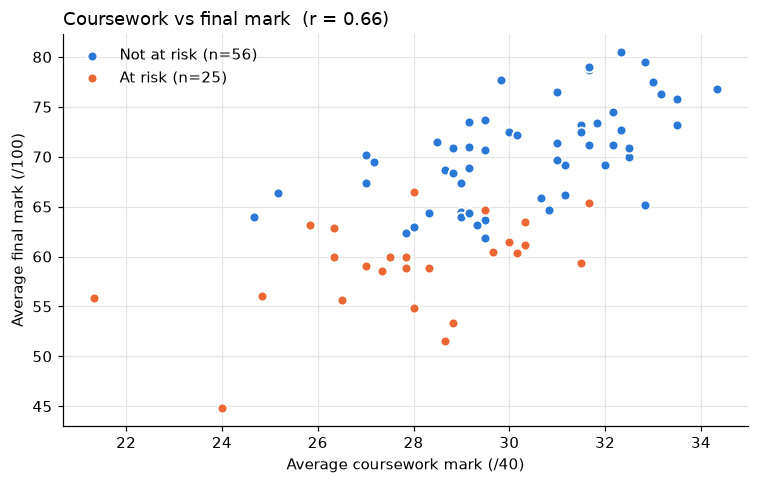

In [15]:
g["scatter"] = perf[["AVG_CW", "AVG_MARK", "AT_RISK", "STUDENT_PROGRAM"]].round(1).values.tolist()
OUT["diagnostic"] = g

fig, ax = plt.subplots(figsize=(7, 4.5))
for flag, col, lab in [(0, BLUE, "Not at risk"), (1, ORANGE, "At risk")]:
    s = perf[perf.AT_RISK == flag]
    ax.scatter(s.AVG_CW, s.AVG_MARK, s=42, color=col, edgecolor="white", linewidth=1.2, label=f"{lab} (n={len(s)})")
ax.set_xlabel("Average coursework mark (/40)"); ax.set_ylabel("Average final mark (/100)")
ax.set_title(f"Coursework vs final mark  (r = {g['corr_avgcw_avgmark']})", loc="left")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

---
## 3. Predictive analysis: *what will happen?*

We train a machine-learning model that looks at a student's profile and estimates the **probability that they will end up at risk**.

### The key design choice: only coursework (CW) as inputs
The model's inputs (**features**) are:
- the 6 **coursework** marks (`CU1_CW` … `CU6_CW`)
- programme (`IS_DITS`), sex (`IS_FEMALE`), and study mode (`STUDY_DAY/EVENING/WEEKEND`)

We deliberately **do not** use exam marks, final marks or grade points. Those only exist **after** the exams, and the at-risk label is built from them. If we used them, the model would be "predicting" something it can already see, a mistake called **data leakage**. It would score close to 100% and be useless in practice. With coursework only, the model can run **mid-semester, before exams**, which is when there is still time to help.

### Step 3.1: build the feature table `X` and the target `y`
**What:** `X` is the table of inputs (one row per student, 11 columns). `y` is the answer we want the model to learn (`AT_RISK`, 0 or 1).

Text columns such as sex or study mode are turned into **0/1 columns** (called "one-hot" or "dummy" encoding), because models only understand numbers. For example, `STUDY_EVENING = 1` means the student studies in the evening.

In [16]:
# EARLY-WARNING framing: predict risk using ONLY information available BEFORE exams
# (coursework marks + study mode + sex + programme). That's what makes it useful.
X = perf[cw_cols].copy()
X["IS_DITS"] = (perf.STUDENT_PROGRAM == "DITS").astype(int)
X["IS_FEMALE"] = (perf.STUDENT_SEX == "F").astype(int)
for t in ["DAY", "EVENING", "WEEKEND"]:
    X[f"STUDY_{t}"] = (perf.STUDY_TIME == t).astype(int)
y = perf.AT_RISK
feat = list(X.columns)
print(X.shape, feat)
X.head()

(81, 11) ['CU1_CW', 'CU2_CW', 'CU3_CW', 'CU4_CW', 'CU5_CW', 'CU6_CW', 'IS_DITS', 'IS_FEMALE', 'STUDY_DAY', 'STUDY_EVENING', 'STUDY_WEEKEND']


,CU1_CW,CU2_CW,CU3_CW,CU4_CW,CU5_CW,CU6_CW,IS_DITS,IS_FEMALE,STUDY_DAY,STUDY_EVENING,STUDY_WEEKEND
0,34.0,29.0,26.0,34.0,33.0,34.0,0,1,0,0,1
1,33.0,26.0,21.0,31.0,28.0,20.0,0,1,0,0,1
2,31.0,23.0,23.0,31.0,35.0,34.0,0,0,0,0,1
3,30.0,30.0,24.0,34.0,33.0,31.0,0,1,1,0,0
4,29.0,27.0,31.0,30.0,33.0,25.0,0,0,0,1,0


### Step 3.2: train/test split (with `stratify`)
**What:** we hide **25% of students (21)** as a **test set** and train on the other **75% (60)**.

**Why:** the honest way to judge a model is on students it has **never seen**, the way it would work on next semester's class. A model tested on its own training data is like a student marking their own homework.

- **`stratify=y`** keeps the same at-risk share (~31%) in both the training and test sets. Without it, by bad luck the 21 test students might contain almost no at-risk students, and the test would be meaningless.
- **`random_state=42`** fixes the random shuffle, so anyone who reruns this gets exactly the same split and the same numbers. The value 42 has no special meaning; what matters is that it is fixed.

In [17]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print("train:", len(X_tr), "students, at-risk share", round(y_tr.mean(), 2))
print("test: ", len(X_te), "students, at-risk share", round(y_te.mean(), 2))

train: 60 students, at-risk share 0.32
test:  21 students, at-risk share 0.29


### Step 3.3: define two models (and `class_weight="balanced"`)
**What:** we compare two common classification models:
- **Logistic Regression**: a simple, transparent model. It draws a straight-line boundary and gives each feature a weight (+ raises risk, − lowers it). `StandardScaler` first puts all features on the same scale so their weights are comparable.
- **Random Forest**: 300 small decision trees, each asking yes/no questions (e.g. "is CU6 coursework < 25?"), which then vote. `max_depth=4` keeps each tree shallow so it cannot just memorise our 60 training students (**overfitting**).

**`class_weight="balanced"`:** only ~31% of students are at risk. A lazy model could say "nobody is at risk" and still be 69% accurate, while catching **zero** at-risk students. `balanced` tells the model that **missing an at-risk student costs more** (in proportion to how rare they are), which pushes it to actually find them.

In [1]:
models = { 
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, class_weight="balanced", random_state=42),
}

NameError: name 'make_pipeline' is not defined

### Step 3.4: train, test and cross-validate
**What:** for each model: train on the 60, predict the 21 test students, and score the predictions.

**The metrics, in plain English** (for the at-risk class):
- **Accuracy**: share of all predictions that were right.
- **Recall**: *of the students who really were at risk, how many did we catch?* **This is the most important one for us.** Missing a struggling student (a false negative) means no help reaches them.
- **Precision**: *of the students we flagged, how many really were at risk?* Low precision means some false alarms. For an early-warning system that is acceptable: an extra mentoring session for a student who did not strictly need it costs little.
- **F1**: a single score that balances recall and precision.

**Cross-validation (`cv_…`):** one test set of 21 students is small and could be lucky or unlucky. **5-fold cross-validation** splits all 81 students into 5 groups, trains on 4 and tests on the 5th, and repeats so each group is the test set once. Then it averages. This gives a **more trustworthy** estimate. `StratifiedKFold` keeps the at-risk share equal in every fold, and `shuffle=True, random_state=42` makes it repeatable.

**How to read the output:** the Random Forest scores **0.90 accuracy / 0.83 recall** on the test set, but **~0.70 accuracy** in cross-validation. The 0.70 is the more honest number. The test set happened to be a relatively easy group of 21 students.

In [19]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
p = {"features": feat, "n_train": int(len(X_tr)), "n_test": int(len(X_te)), "models": {}}
for name, m in models.items():
    m.fit(X_tr, y_tr); pr = m.predict(X_te)
    p["models"][name] = {
        "accuracy": round(accuracy_score(y_te, pr), 2), "recall": round(recall_score(y_te, pr), 2),
        "precision": round(precision_score(y_te, pr, zero_division=0), 2), "f1": round(f1_score(y_te, pr), 2),
        "cv_recall": round(cross_val_score(m, X, y, cv=cv, scoring="recall").mean(), 2),
        "cv_accuracy": round(cross_val_score(m, X, y, cv=cv, scoring="accuracy").mean(), 2),
        "confusion": confusion_matrix(y_te, pr).tolist()}
pd.DataFrame(p["models"]).T.drop(columns="confusion")

,accuracy,recall,precision,f1,cv_recall,cv_accuracy
Logistic Regression,0.81,1.0,0.6,0.75,0.68,0.67
Random Forest,0.9,0.83,0.83,0.83,0.56,0.7


### Step 3.5: confusion matrix (Random Forest, test set)
**What:** a 2×2 table of what the model predicted against what actually happened, for the 21 test students.

**How to read it:**
- **Top-left (true negatives):** not at risk, correctly left alone.
- **Bottom-right (true positives):** at risk, correctly flagged. **These are the students we help.**
- **Bottom-left (false negatives):** at risk but **missed**. This is the costly error.
- **Top-right (false positives):** flagged but actually fine. A false alarm, which costs little.

The Random Forest caught **5 of the 6** at-risk test students (recall 5/6 = 0.83) and raised **1** false alarm. For comparison, Logistic Regression caught all 6 (recall 1.0) but raised 4 false alarms.

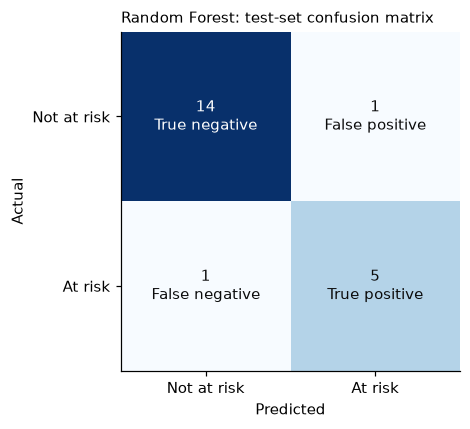

In [20]:
cm = np.array(p["models"]["Random Forest"]["confusion"])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
names = [["True negative", "False positive"], ["False negative", "True positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b", fontsize=10)
ax.set_xticks([0, 1], ["Not at risk", "At risk"]); ax.set_yticks([0, 1], ["Not at risk", "At risk"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Random Forest: test-set confusion matrix", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

### Step 3.6: refit on all 81 students and look at feature importance
**What:** once we have *measured* the model on held-out data, we retrain it on **all 81 students**. The final model then learns from every example we have, as is standard practice. The scores from Step 3.4 remain our estimate of its performance.

**Feature importance** (Random Forest) shows how much each input helped the trees separate at-risk from not-at-risk students. The values add up to 1.

**How to read the chart:** **CU6 coursework is the most important signal**, which matches the diagnostic finding that CU6 drives failures. Then come CU2 and CU3 coursework, and programme (`IS_DITS`). **Sex and study mode contribute very little** (together under 7%), so the model is driven mainly by academic performance, not demographics.

The Logistic Regression coefficients tell the same story. Every coursework weight is **negative**, meaning better coursework lowers the risk. `IS_DITS` is also strongly negative (being in DITS lowers risk).

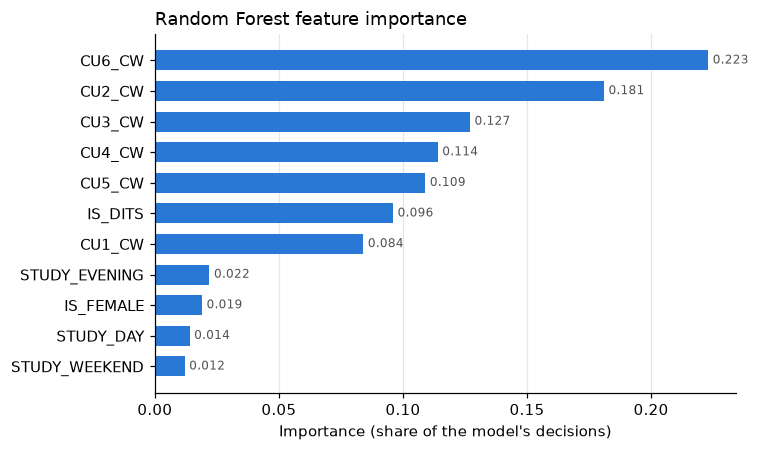

Logistic Regression coefficients: {'CU1_CW': -0.65, 'CU2_CW': -0.23, 'CU3_CW': -0.56, 'CU4_CW': -0.6, 'CU5_CW': -0.17, 'CU6_CW': -0.54, 'IS_DITS': -0.92, 'IS_FEMALE': -0.24, 'STUDY_DAY': -0.05, 'STUDY_EVENING': 0.19, 'STUDY_WEEKEND': -0.11}


In [21]:
rf = models["Random Forest"].fit(X, y)                      # refit best-explained model on all data
lr = models["Logistic Regression"].fit(X, y)
imp = sorted(zip(feat, rf.feature_importances_), key=lambda t: -t[1])
p["importance"] = [[f, round(float(v), 3)] for f, v in imp]
p["lr_coef"] = dict(zip(feat, np.round(lr[-1].coef_[0], 2).tolist()))

fig, ax = plt.subplots(figsize=(7, 4.2))
names_, vals_ = zip(*p["importance"][::-1])
bars = ax.barh(names_, vals_, color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.3f", fontsize=8, color="#52514e", padding=3)
ax.set_xlabel("Importance (share of the model's decisions)"); ax.grid(axis="y", visible=False)
ax.set_title("Random Forest feature importance", loc="left"); plt.tight_layout(); plt.show()
print("Logistic Regression coefficients:", p["lr_coef"])

### Step 3.7: score every student and save the model
**What:** `predict_proba` gives each student a **risk probability** between 0 and 1. The model and its feature list are saved to `model.joblib`, so they can be reloaded later to score new students without retraining.

**Caveat:** these probabilities come from a model that was trained on these same 81 students, so they look more confident than they would on brand-new students.

In [22]:
perf["RISK_PROB"] = rf.predict_proba(X)[:, 1]
joblib.dump({"model": rf, "features": feat}, "model.joblib")
OUT["predictive"] = p
perf[["STUDENT_NO", "STUDENT_PROGRAM", "AVG_CW", "AT_RISK", "RISK_PROB"]].sort_values("RISK_PROB", ascending=False).head().round(2)

,STUDENT_NO,STUDENT_PROGRAM,AVG_CW,AT_RISK,RISK_PROB
26,S0001033,DITB,24.83,1,0.94
5,S0000722,DITB,27.50,1,0.92
11,S0000776,DITB,26.33,1,0.90
38,S0001154,DITB,24.00,1,0.89
1,S0000507,DITB,26.50,1,0.88


---
## 4. Prescriptive analysis: *what should we do?*

Predictions are only useful if they lead to action. Here every student's risk probability is turned into a **support tier** and a concrete recommendation.

### Step 4.1: the rules for tiers and actions
**What:** a simple, transparent rule for each student:
- **High** (risk ≥ 0.7): assign an academic mentor plus weekly check-ins before exams
- **Medium** (0.4 to 0.7): targeted revision clinics in weak units
- **Low** (< 0.4): standard support; could act as a peer tutor

On top of the tier, any unit where the student's coursework is **below 25/40 (62.5%)** is named as a **remedial focus**.

**Why rules, not another model:** staff need to understand and trust *why* a student was placed in a tier. Thresholds that can be read and adjusted are easier to explain and defend than a black box.

In [23]:
def recommend(r):
    weak = [c for c in CUS if r[f"{c}_CW"] < 25]            # coursework below 25/40 (62.5%)
    if r.RISK_PROB >= 0.7: tier, act = "High", "Assign academic mentor + weekly check-ins before exams"
    elif r.RISK_PROB >= 0.4: tier, act = "Medium", "Targeted revision clinics in weak units"
    else: tier, act = "Low", "Standard support; consider peer-tutor role"
    if weak: act += f"; remedial focus: {', '.join(weak)}"
    return pd.Series({"TIER": tier, "ACTION": act})

### Step 4.2: apply the rules, count tiers, and pick priority units
**What:** gives every student a tier and an action, counts students per tier, and lists the 2 units with the most fails/retakes as **institution-level priorities**.

**How to read it:** **18 High, 14 Medium, 49 Low.** The priority units are **CU6** and CU1. In practice the main institutional action is to **review CU6** (its teaching, exam design and revision support), since it causes most failures. CU1 comes second only through a tie-break: CU1, CU3 and CU5 each have just 1 case.

In [24]:
perf[["TIER", "ACTION"]] = perf.apply(recommend, axis=1)
rx = {}
rx["tier_counts"] = perf.TIER.value_counts().reindex(["High", "Medium", "Low"]).fillna(0).astype(int).to_dict()
rx["priority_cus"] = [c for c, _ in sorted(zip(CUS, g["cu_fail_count"]), key=lambda t: -t[1])][:2]
print("tiers:", rx["tier_counts"], "| priority units:", rx["priority_cus"])

tiers: {'High': 18, 'Medium': 14, 'Low': 49} | priority units: ['CU6', 'CU1']


### Step 4.3: the watchlist (top 15) and the output file
**What:** the 15 highest-risk students with their tier and recommended action. All 81 students, with scores, tiers and actions, are saved to `student_risk_scores.csv`. That file is the main deliverable a student-affairs office would use.

**How to read it:** most of the watchlist are DITB students, matching the 51% vs 14% gap. Most have CU6 as a remedial focus.

In [25]:
rx["watchlist"] = perf.sort_values("RISK_PROB", ascending=False)[
    ["STUDENT_NO", "STUDENT_PROGRAM", "STUDY_TIME", "AVG_CW", "RISK_PROB", "AT_RISK", "TIER", "ACTION"]
].round(2).head(15).values.tolist()
perf.to_csv("student_risk_scores.csv", index=False)
OUT["prescriptive"] = rx
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rx["watchlist"], columns=["STUDENT_NO", "PROGRAM", "STUDY_TIME", "AVG_CW", "RISK_PROB", "AT_RISK", "TIER", "ACTION"])

,STUDENT_NO,PROGRAM,STUDY_TIME,AVG_CW,RISK_PROB,AT_RISK,TIER,ACTION
0,S0001033,DITB,DAY,24.83,0.94,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU2, CU3, CU6"
1,S0000722,DITB,DAY,27.50,0.92,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU3, CU6"
2,S0000776,DITB,EVENING,26.33,0.90,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU2, CU6"
3,S0001154,DITB,DAY,24.00,0.89,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU2, CU6"
4,S0000507,DITB,WEEKEND,26.50,0.88,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU3, CU6"
5,S0000735,DITB,DAY,27.33,0.87,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU2, CU3, CU6"
6,S0000942,DITB,DAY,26.33,0.86,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU2, CU6"
7,S0001069,DITB,WEEKEND,28.00,0.86,1,High,Assign academic mentor + weekly check-ins before exams; remedial focus: CU3
8,S0000968,DITB,EVENING,29.50,0.85,1,High,Assign academic mentor + weekly check-ins before exams; remedial focus: CU6
9,S0000925,DITB,EVENING,27.83,0.85,1,High,"Assign academic mentor + weekly check-ins before exams; remedial focus: CU4, CU6"


---
## 5. Appendix: context datasets (not linked to students)

The LMS-usage and digital-skills-survey datasets come from **different years and populations**, and they share **no student ID** with the performance files. So we **cannot** join them to individual students or use them in the model. We summarise them only as **background context** on digital engagement at UICT.

### Step 5.1: LMS (Learning Management System) usage
**What:** cleans broken characters out of the text, converts "last login" text (e.g. "1 year 54 days") into a number of days, drops corrupted rows, keeps learner accounts only, and then summarises how recently learners logged in.

**How to read it:** about **20% of learner accounts never logged in at all**, and some courses have far higher "never logged in" rates. This suggests low LMS engagement, which could be worth tracking as a future early-warning signal if it could be linked to students.

In [26]:
lms = pd.read_csv(UP + "Learner management system usage.csv", encoding="latin1")
clean = lambda s: re.sub(r"[^\x20-\x7E]", "", str(s)).strip(' "')
lms["ROLE"] = lms.USER_ROLE.map(clean).str.title()
def days(s):
    s = clean(s)
    if s == "Never": return np.nan
    y = re.search(r"(\d+) year", s); dd = re.search(r"(\d+) day", s)
    if not (y or dd or re.search(r"hour|min|sec", s)): return None   # junk/shifted rows
    return (int(y.group(1)) * 365 if y else 0) + (int(dd.group(1)) if dd else 0)
lms["DAYS"] = lms.LAST_LOGIN.map(days)
lms["NEVER"] = lms.LAST_LOGIN.map(clean).eq("Never")
lms = lms[lms.NEVER | lms.DAYS.notna()]
stu = lms[lms.ROLE.str.contains("Student|Participant|Learner")]
L = {"records": int(len(lms)), "learner_records": int(len(stu)),
     "never_pct": round(stu.NEVER.mean() * 100, 1)}
def bucket(r):
    if r.NEVER: return "Never logged in"
    return "< 1 year" if r.DAYS < 365 else ("1-2 years" if r.DAYS < 730 else "2+ years")
stu = stu.assign(B=stu.apply(bucket, axis=1))
order = ["< 1 year", "1-2 years", "2+ years", "Never logged in"]
L["recency"] = stu.B.value_counts().reindex(order).fillna(0).astype(int).tolist(); L["recency_labels"] = order
cu = stu.groupby(stu.COURSE_NAME.map(clean)).agg(n=("NEVER", "size"), never=("NEVER", "mean"))
cu = cu[cu.n >= 30].sort_values("never", ascending=False)
L["course_never"] = [[k, int(r.n), round(r.never * 100, 1)] for k, r in cu.iterrows()][:10]
OUT["lms"] = L
print({k: L[k] for k in ["records", "learner_records", "never_pct"]}, dict(zip(order, L["recency"])))
pd.DataFrame(L["course_never"], columns=["course", "learners", "% never logged in"])

{'records': 1932, 'learner_records': 1840, 'never_pct': np.float64(20.0)} {'< 1 year': 252, '1-2 years': 669, '2+ years': 551, 'Never logged in': 368}


,course,learners,% never logged in
0,ICT in Education,56,64.3
1,Essential IT Skills Development for Non-IT Professionals,33,57.6
2,LEADERSHIP SKILLS DEVELOPMENT FOR ICT PROFESSIONALS,38,42.1
3,Support for Development of Human Resources-ENABEL,173,37.0
4,Computer Workshop Practice,40,35.0
5,CLOUD COMPUTING -AWS,129,30.2
6,Digital Literacy Skills transfer Project,56,23.2
7,Website Development II,204,19.6
8,Data Communication and Networking II,228,9.6
9,Computer Workshop Practice I,187,9.6


### Step 5.2: digital-skills survey
**What:** keeps rows with a valid Yes/No internet answer (rows that were shifted by bad CSV quoting are dropped), groups free-text occupations into 3 categories, and counts themes in what respondents expect from training.

**How to read it:** **97% report internet access**, and the most common expectation is **gaining skills/knowledge**, followed by jobs/employment. This is context on the wider digital-skilling audience, not on our 81 students.

In [27]:
sv = pd.read_csv(UP + "students_survey_data digital skilling.csv")
sv = sv[sv.INTERNET_ACCESS.isin(["Yes", "No"])]          # drop rows shifted by bad CSV quoting
occ = sv.OCCUPATION.astype(str).str.strip().str.lower()
sv["OCC"] = np.select([occ.str.contains("teach|tutor|lecturer|trainer"),
                       occ.str.contains("stud|vac|s.6|s6|learner|school")], ["Teacher/Trainer", "Student"], "Other/Working")
exp = sv.EXPECTATIONS.astype(str).str.lower()
themes = {"Skills/knowledge": "skill|knowledge|literate|basic|learn", "Certificate": "certif",
          "Job/employment": "job|employ|work|earn|living", "Business": "business|self employ|creat",
          "Cyber security": "cyber|security", "Programming/networking": "program|network|coding"}
S = {"n": int(len(sv)), "gender": sv.GENDER.value_counts().to_dict(),
     "internet_yes_pct": round((sv.INTERNET_ACCESS == "Yes").mean() * 100, 1),
     "occupation": sv.OCC.value_counts().to_dict(),
     "top_districts": sv.DISTRICT.astype(str).str.strip().str.title().value_counts().head(8).to_dict(),
     "expectations": {k: int(exp.str.contains(v).sum()) for k, v in themes.items()}}
OUT["survey"] = S
S

{'n': 278,
 'gender': {'Male': 209, 'Female': 69},
 'internet_yes_pct': np.float64(97.1),
 'occupation': {'Student': 115, 'Teacher/Trainer': 100, 'Other/Working': 63},
 'top_districts': {'Kampala': 41,
  'Wakiso': 38,
  'Mbale': 11,
  'Kyotera': 11,
  'Mukono': 10,
  'Lira': 9,
  'Jinja': 8,
  'Masaka': 7},
 'expectations': {'Skills/knowledge': 174,
  'Certificate': 28,
  'Job/employment': 68,
  'Business': 11,
  'Cyber security': 10,
  'Programming/networking': 13}}

### Save all results
**What:** writes every result to `results.json` (the same file `analysis.py` produces), then checks that the headline numbers match the script.

In [28]:
json.dump(OUT, open("results.json", "w"), indent=1, default=str)
rf_m = OUT["predictive"]["models"]["Random Forest"]
assert OUT["descriptive"]["students_complete"] == 81
assert OUT["descriptive"]["at_risk_rate"] == 30.9
assert OUT["diagnostic"]["cu_fail_count"][5] == 16 and sum(OUT["diagnostic"]["cu_fail_count"]) == 19
assert (rf_m["accuracy"], rf_m["recall"], rf_m["cv_accuracy"]) == (0.9, 0.83, 0.7)
print("All headline results match analysis.py")

All headline results match analysis.py
